# Extension: best strategies per opponent strength
The main analysis (`results.ipynb`) finds the best 4th-down strategy against an **equal** opponent. Here we repeat steps 1 and 2 against a **weak** and a **strong** opponent (plays drawn only from the bottom / top third of teams by EPA per play), with the same candidates (7,392), field-goal range (57 yards) and rule parameters, so the three are comparable.

Computed by `opponents_compute.py` (about 40 minutes), saved in `results_opponents.json`. All gains are in percentage points of win probability **over real coaches facing the same opponent**.

In [1]:
import pandas as pd
import model as M
import plots_opponents as PO

r = M.load_results("results_opponents.json")
OPPS = PO.OPPS

def row(o):
    f = r[f"{o}/final"]
    single = f.loc[f"Best single rule (X = {r[f'{o}/best_x']})"]
    best, eq = f.loc[r[f"{o}/best_name"]], f.loc[r[f"{o}/equal_winner"]]
    return {"coaches win": r[f"{o}/singles"].loc["1. Real coaches", "p̂"],
            "best single rule": f"go if ≤ {r[f'{o}/best_x']} yd: {single['diff (pp)']:+.2f} [{single['diff lower']:+.2f}, {single['diff upper']:+.2f}]",
            "best combination": r[f"{o}/best_name"],
            "its gain": f"{best['diff (pp)']:+.2f} [{best['diff lower']:+.2f}, {best['diff upper']:+.2f}]",
            "equal-opponent winner's gain": f"{eq['diff (pp)']:+.2f} [{eq['diff lower']:+.2f}, {eq['diff upper']:+.2f}]"}

pd.set_option("display.max_colwidth", None)
pd.DataFrame({o: row(o) for o in OPPS})

,weak,equal,strong
coaches win,0.657167,0.501117,0.349867
best single rule,"go if ≤ 6 yd: +2.44 [+1.91, +2.97]","go if ≤ 6 yd: +4.29 [+3.70, +4.87]","go if ≤ 6 yd: +4.93 [+4.39, +5.46]"
best combination,≤5 yd & pos ≤90 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤2 drives) | else kick,≤5 yd & pos ≤95 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,≤6 yd & pos ≤90 + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick
its gain,"+3.32 [+2.80, +3.85]","+4.49 [+3.91, +5.07]","+5.29 [+4.75, +5.83]"
equal-opponent winner's gain,"+3.26 [+2.73, +3.78]","+4.49 [+3.91, +5.07]","+5.00 [+4.46, +5.54]"


## Step 1: each single strategy against each opponent (30,000 paired games)

In [2]:
pd.DataFrame({o: r[f"{o}/singles"]["diff (pp)"].values for o in OPPS},
             index=[s.split(' (')[0] for s in r["equal/singles"].index]).round(2)

,weak,equal,strong
1. Real coaches,0.00,0.00,0.00
2. Never,-3.84,-3.56,-3.78
3. Always,-5.55,-2.44,0.48
4. Fixed rate,-4.20,-3.79,-2.64
5. Short yardage,2.26,4.19,5.48
6. Past midfield,-0.23,0.89,1.25
7. Short and close,2.26,4.19,5.48
8. No man's land,-3.60,-3.26,-3.12
9. Goal line,-2.89,-2.46,-2.68
10. Trailing late,-0.21,0.58,1.67


## Step 2: best combination per opponent (successive halving, then 50,000 fresh paired games)
Each opponent's own top 5 next to the equal-opponent winner and the best single rule; the best one wins.

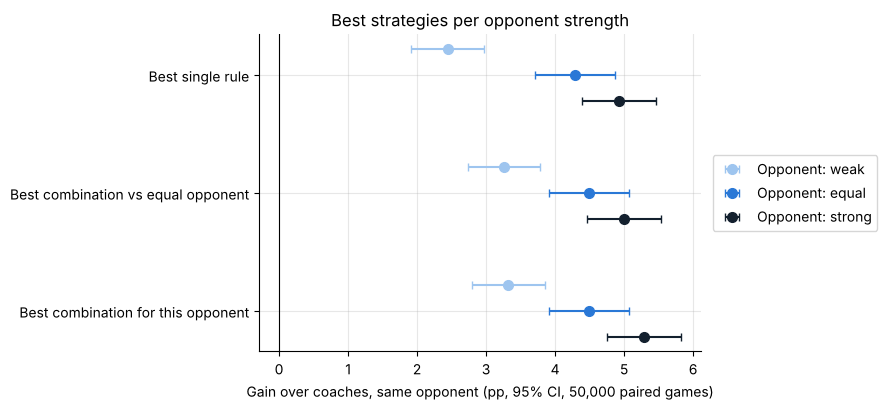

In [3]:
PO.summary(r)

In [4]:
for o in OPPS:
    display(r[f"{o}/final"][["p̂", "diff (pp)", "diff lower", "diff upper", "go %"]].round(3).rename_axis(o))

,p̂,diff (pp),diff lower,diff upper,go %
weak,,,,,
≤5 yd & pos ≤90 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤2 drives) | else kick,0.689,3.323,2.799,3.847,53.679
≤5 yd & pos ≤90 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) | else kick,0.689,3.280,2.755,3.805,54.347
≤5 yd & pos ≤90 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.689,3.304,2.779,3.829,54.006
≤5 yd & pos ≤90 + no man's land 50–60 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤2 drives) | else kick,0.689,3.321,2.797,3.845,52.800
≤5 yd & pos ≤90 + no man's land 50–60 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.689,3.310,2.785,3.835,53.126
≤5 yd & pos ≤95 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.689,3.257,2.732,3.782,54.218
Best single rule (X = 6),0.681,2.444,1.915,2.973,56.813


,p̂,diff (pp),diff lower,diff upper,go %
equal,,,,,
≤5 yd & pos ≤95 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.547,4.486,3.906,5.066,55.399
≤5 yd & pos ≤90 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.547,4.472,3.892,5.052,55.225
≤5 yd & pos ≤90 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤2 drives) | else kick,0.547,4.429,3.849,5.009,54.875
≤5 yd & pos ≤90 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) | else kick,0.547,4.460,3.880,5.040,55.612
≤5 yd & pos ≤95 + no man's land 40–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.547,4.438,3.858,5.018,54.992
Best single rule (X = 6),0.545,4.285,3.705,4.865,56.758


,p̂,diff (pp),diff lower,diff upper,go %
strong,,,,,
≤6 yd & pos ≤90 + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.406,5.287,4.747,5.827,61.070
≤6 yd & pos ≤90 + trailing (≤2 drives) | else kick,0.406,5.268,4.729,5.807,61.469
≤6 yd & pos ≤95 + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.406,5.279,4.740,5.818,61.311
≤6 yd & pos ≤85 + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.406,5.253,4.714,5.792,60.425
≤6 yd & pos ≤90 + trailing (≤2 drives) + score-changing FG (≤2 drives) | else kick,0.406,5.265,4.726,5.804,60.690
≤5 yd & pos ≤95 + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤1 drives) | else kick,0.404,5.001,4.461,5.541,56.665
Best single rule (X = 6),0.403,4.926,4.388,5.464,56.701


## The handbook against each opponent
The best combination's call on every 4th down in a normal situation (tied game, not late). Where a strategy falls back to the coaches, the map shows the coaches' most common call.

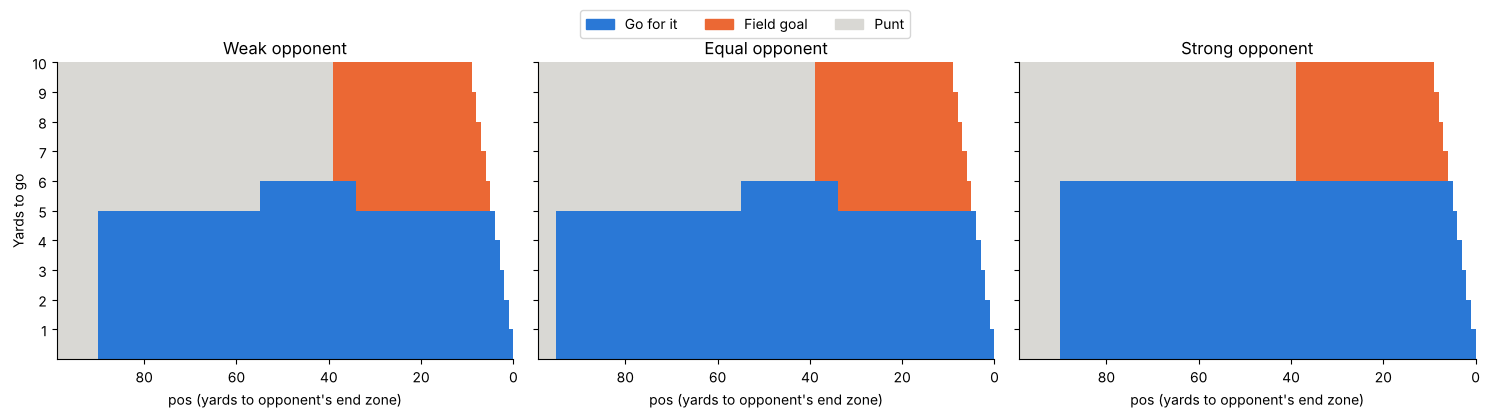

In [5]:
m = M.estimate(M.load_data())
PO.handbooks(r, m, M.load_results("results.json")["fg_range"])